# ATRO — Order Agent: Dataset → Preprocessing → Model Training → Groq LLM → ATRO Scoring

**Adaptive Trust & Risk Orchestrator — Order Agent (full pipeline)**

This notebook runs the whole Order Agent flow end to end:

1. **Dataset choice** — which of the project's datasets the Order Agent actually uses.
2. **Preprocessing** — Dataset 1 (Customer Support Q&A) is filtered to order-related rows, intent-labelled, cleaned and de-duplicated.
3. **Model training** — a TF-IDF + Logistic Regression **intent classifier** is trained, cross-validated, tested on a hold-out set and saved. A second public dataset (Bitext customer support) is tried as extra training data and kept only if it does not hurt accuracy on Dataset 1. A rule-based safety net keeps cancellation and modification requests from ever being downgraded.
4. **Groq LLM** — grounded response generation from verified order data (`openai/gpt-oss-20b`).
5. **ATRO scoring** — Trust, Evidence, Hallucination Reliability, Conflict and Risk combine into the Decision Intelligence score, and a four-way decision engine picks `ACCEPT / VERIFY / RE-ROUTE / ESCALATE`.
6. **LangGraph + RAG + dynamic Trust** — the pipeline is a LangGraph state graph, replies draw on a FAISS knowledge base built from Dataset 1's own answers, and Trust changes during a session.

Run the cells top to bottom. You need a Groq API key (free at console.groq.com). Dataset 1 is your own CSV (`Customer Support Data Set - Sheet1 (1).csv`): upload it when the notebook asks.

**What "training" means here.** Only the intent classifier is trained. The Groq model is used as is, and the ATRO weights (0.25) and thresholds are fixed design values, not learned.

## 0. Setup

In [ ]:
!pip install -q groq ftfy langgraph faiss-cpu sentence-transformers scikit-learn joblib kagglehub datasets matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.8/143.8 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 75.3 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import re
import ftfy
import random
from getpass import getpass

random.seed(42)
np.random.seed(42)

pd.set_option("display.max_colwidth", 120)

## 1. Which Dataset Does the Order Agent Use?

| Dataset | What it holds | Used by the Order Agent? |
|---|---|---|
| **Customer Support Q&A** (Kaggle, `timkeating`) | Customer support questions and answers with a `category` column that includes *Orders*, *Shipping* and *Order Management* | **Yes — this is Dataset 1.** It is the only text dataset in the list about orders and shipping. |
| DeepFashion2 | Clothing images with detection and landmark annotations | No — image data, no support text |
| Fashionpedia | Fashion images with attribute annotations | No — image data |
| Polyvore | Outfit and fashion-item compatibility data | No — not order or support related |
| Amazon Fashion Reviews | Product review text | Not for orders. Review text fits an agent that handles product feedback or returns better |
| Prompt-injection vs benign prompts | Prompts labelled as injection attempts or benign | Optional — could act as a shared input guard in front of every agent, but it is not Order Agent training data |

**Supplementary training data:** the notebook also tries the public Bitext customer-support dataset (Hugging Face) to add more labelled examples for the intent classifier (Section 3). It is not one of the six project datasets.

The descriptions come from the dataset titles; check them against each dataset page and your team's dataset-to-agent plan.

Dataset 1 has no real orders, so a small **synthetic order database** (Section 4) stands in for the order system.

## 2. Load and Preprocess Dataset 1

Steps: load the CSV, keep the order-related categories, label each question with an intent using keyword rules, fix encoding problems, decide which rows belong to the Order Agent, remove duplicates, and save the result.

This mirrors the preprocessing already done in your Colab notebook, so the intent distribution should land close to the earlier report (the comparison is printed below).

In [ ]:
import os, glob

REQUIRED_COLUMNS = {"question", "answer", "category"}
ORDER_CATEGORY_NAMES = {"orders", "shipping", "order management"}


def _read_if_valid(path):
    # Accept only a CSV with question/answer/category columns that really contains
    # the Orders / Shipping / Order Management categories (not our own saved output).
    try:
        d = pd.read_csv(path)
    except Exception:
        return None
    d.columns = [c.strip().lower() for c in d.columns]
    if "intent" in d.columns or not REQUIRED_COLUMNS.issubset(d.columns):
        return None
    cats = set(d["category"].astype(str).str.strip().str.lower())
    return d if cats & ORDER_CATEGORY_NAMES else None


raw_df = None

# 1) a matching CSV already in the working folder
for f in glob.glob("/content/*.csv") + glob.glob("*.csv"):
    raw_df = _read_if_valid(f)
    if raw_df is not None:
        print("Loaded local file:", f)
        break

# 2) otherwise ask for an upload: choose "Customer Support Data Set - Sheet1 (1).csv"
if raw_df is None:
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        raw_df = _read_if_valid(name)
        if raw_df is not None:
            print("Loaded uploaded file:", name)
            break

assert raw_df is not None, (
    "No CSV with question / answer / category columns and Orders / Shipping / "
    "Order Management categories was found. Upload Customer Support Data Set - Sheet1 (1).csv"
)
print("Raw dataset shape:", raw_df.shape)
print(raw_df["category"].value_counts())
raw_df.head()

Saving Customer_Support_Order_Questions_Reconstructed.csv to Customer_Support_Order_Questions_Reconstructed.csv
Loaded uploaded file: Customer_Support_Order_Questions_Reconstructed.csv
Raw dataset shape: (260, 3)
category
Orders              143
Shipping            106
Order Management     11
Name: count, dtype: int64


,question,answer,category
0,Where is my order?,Where is my order?,Shipping
1,"My package hasn't arrived yet, what should I do?","My package hasn't arrived yet, what should I do?",Shipping
2,Do you offer free shipping?,Do you offer free shipping?,Shipping
3,I entered the wrong shipping address. Can I change it?,I entered the wrong shipping address. Can I change it?,Shipping
4,How long does shipping take?,How long does shipping take?,Shipping


In [ ]:
def normalize_text(text):
    """Fix encoding problems, lowercase, drop markdown symbols, collapse spaces."""
    text = ftfy.fix_text(str(text))
    text = text.lower()
    text = re.sub(r"[*_`#]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


df = raw_df.copy()
print("Missing values:\n", df[["question", "answer", "category"]].isna().sum())
print("Duplicate rows:", df.duplicated().sum())

# keep only the categories that belong to order handling
# (compared in lower case with spaces trimmed, so "Orders " or "orders" still match)
ORDER_CATEGORIES = ["orders", "shipping", "order management"]
df["category"] = df["category"].astype(str).str.strip()
df = df[df["category"].str.lower().isin(ORDER_CATEGORIES)].copy()
print("Order-related rows:", df.shape[0])
assert df.shape[0] > 0, (
    "No rows matched the order categories. The categories found in this file are: "
    + str(sorted(raw_df["category"].astype(str).unique()))
    + " - edit ORDER_CATEGORIES above to match the right ones."
)

Missing values:
 question    0
answer      0
category    0
dtype: int64
Duplicate rows: 10
Order-related rows: 260


### Intent labelling (weak supervision)

The dataset has a `category` but no intent column, so intents are assigned with keyword rules. Rules run in order and **later rules override earlier ones**. The last few rules are corrections found while reviewing the labels by hand.

These labels are good enough to train a classifier, but they are not human-verified. Keep that in mind when reading the accuracy numbers in Section 3.

In [ ]:
df["intent"] = "ORDER_OTHER"

LABEL_RULES = [
    ("ORDER_TRACKING", r"track|tracking number|tracking link|tracking updates|real-time tracking"),
    ("MISSING_OR_LOST_ORDER", r"lost|missing|didn.t get|hasn.t arrived|partially missing|partially fulfilled"),
    ("ORDER_CANCELLATION", r"cancel|cancellation"),
    ("ORDER_MODIFICATION", r"change.*address|change.*color|change.*size|change.*shipping method|change.*delivery method|add items|special instructions"),
    ("ORDER_STATUS", r"where is my order|order status|order confirmed|order confirmation|order confirmation email|order was confirmed|order is confirmed|processing for days|when my order ships|when.*order.*ship"),
    ("DELIVERY", r"when.*arrive|delivery date|delivery time|schedule.*delivery|specific delivery|weekend delivery|holiday delivery"),
    ("ORDER_DETAILS", r"invoice|receipt"),
    ("SHIPPING", r"free shipping|express shipping|shipping take|ship internationally|ship on weekends|shipping costs|shipping fees|shipping carrier|specific courier|shipping discounts|bulk shipping"),
    # corrections
    ("ORDER_MODIFICATION", r"wrong.*shipping address|change.*address|change.*delivery address"),
    ("ORDER_MODIFICATION", r"combine multiple orders|combine multiple orders into one"),
    ("DELIVERY", r"shipment is delayed|shipping delay|delivery delayed"),
    ("SHIPPING", r"pick up my order|pickup.*order"),
    ("SHIPPING", r"expedited processing|express handling|expedited shipping"),
]

for intent, pattern in LABEL_RULES:
    mask = df["question"].str.contains(pattern, case=False, na=False, regex=True)
    df.loc[mask, "intent"] = intent

df["intent"].value_counts()

,count
intent,
ORDER_OTHER,104
SHIPPING,42
ORDER_MODIFICATION,37
ORDER_TRACKING,24
MISSING_OR_LOST_ORDER,14
DELIVERY,11
ORDER_CANCELLATION,11
ORDER_DETAILS,10
ORDER_STATUS,7


In [ ]:
# Clean the text (fixes broken characters such as "isn‚Äôt")
df["question_clean"] = df["question"].apply(normalize_text)
df["answer_clean"] = df["answer"].apply(normalize_text)

# Scope: every labelled row belongs to the Order Agent ...
df["agent_scope"] = "OTHER_AGENT"
df.loc[df["intent"] != "ORDER_OTHER", "agent_scope"] = "ORDER_AGENT"

# ... plus unlabelled rows that are still clearly about orders
order_other_patterns = (
    r"pre-order|preorder|"
    r"reorder.*order|reorder.*purchase|reorder.*item|"
    r"previous order|previous purchase|"
    r"order.*shipped|shipped.*order|"
    r"order updates|"
    r"pre-order.*notification|"
    r"pre-order.*ship|"
    r"package hasn.t arrived|"
    r"item arrived late|"
    r"courier.*shipment|"
    r"shipment.*notification|"
    r"shipping.*notification|"
    r"order.*notification"
)
df.loc[
    (df["intent"] == "ORDER_OTHER")
    & df["question_clean"].str.contains(order_other_patterns, case=False, na=False, regex=True),
    "agent_scope",
] = "ORDER_AGENT"

# Final label fixes for the remaining ORDER_OTHER rows
FINAL_FIXES = [
    ("MISSING_OR_LOST_ORDER", r"package hasn't arrived|package hasnt arrived"),
    ("SHIPPING", r"pre-order items shipped|preorder items shipped"),
    ("ORDER_STATUS", r"how do i know my order has shipped|order has shipped"),
    ("SHIPPING", r"courier.*shipment|specific courier"),
    ("ORDER_STATUS", r"notifications for order updates|order update notifications"),
]
for intent, pattern in FINAL_FIXES:
    mask = df["question_clean"].str.contains(pattern, case=False, na=False, regex=True)
    df.loc[mask, "intent"] = intent

print(df["agent_scope"].value_counts())

agent_scope
ORDER_AGENT    180
OTHER_AGENT     80
Name: count, dtype: int64


In [ ]:
order_agent_df = (
    df[df["agent_scope"] == "ORDER_AGENT"][["question_clean", "answer_clean", "category", "intent"]]
    .rename(columns={"question_clean": "question", "answer_clean": "answer"})
    .dropna(subset=["question", "answer"])
    .copy()
)

before = len(order_agent_df)
order_agent_df = order_agent_df.drop_duplicates(subset=["question"]).reset_index(drop=True)
print(f"Order Agent rows: {before} -> {len(order_agent_df)} after removing duplicate questions")

# Compare with the distribution reported earlier (180 records)
EARLIER_REPORT = {
    "SHIPPING": 44, "ORDER_MODIFICATION": 37, "ORDER_TRACKING": 24, "ORDER_OTHER": 19,
    "MISSING_OR_LOST_ORDER": 15, "DELIVERY": 11, "ORDER_CANCELLATION": 11,
    "ORDER_DETAILS": 10, "ORDER_STATUS": 9,
}
compare = pd.DataFrame({
    "now": order_agent_df["intent"].value_counts(),
    "earlier_report": pd.Series(EARLIER_REPORT),
}).fillna(0).astype(int)
compare["difference"] = compare["now"] - compare["earlier_report"]
print(compare)
print("Total:", compare["now"].sum(), "(earlier report: 180)")

order_agent_df.to_csv("order_agent_preprocessed.csv", index=False)
print("Saved order_agent_preprocessed.csv")
order_agent_df.head()

Order Agent rows: 180 -> 174 after removing duplicate questions
                       now  earlier_report  difference
SHIPPING                41              44          -3
ORDER_MODIFICATION      36              37          -1
ORDER_TRACKING          24              24           0
ORDER_OTHER             19              19           0
MISSING_OR_LOST_ORDER   15              15           0
DELIVERY                11              11           0
ORDER_CANCELLATION      11              11           0
ORDER_DETAILS            9              10          -1
ORDER_STATUS             8               9          -1
Total: 174 (earlier report: 180)
Saved order_agent_preprocessed.csv


,question,answer,category,intent
0,where is my order?,where is my order?,Shipping,ORDER_STATUS
1,"my package hasn't arrived yet, what should i do?","my package hasn't arrived yet, what should i do?",Shipping,MISSING_OR_LOST_ORDER
2,do you offer free shipping?,do you offer free shipping?,Shipping,SHIPPING
3,i entered the wrong shipping address. can i change it?,i entered the wrong shipping address. can i change it?,Shipping,ORDER_MODIFICATION
4,how long does shipping take?,how long does shipping take?,Shipping,SHIPPING


## 3. Train the Intent Classifier

The classifier reads a customer query and predicts one of the 9 order intents. Everything downstream depends on it: the intent decides which facts must appear in the answer (Evidence) and how risky the request is (Risk).

**Method:** TF-IDF features (word 1-2 grams plus character 2-5 grams) feed a linear classifier. Three candidates are compared with stratified cross-validation. A second dataset is then tested as extra training data, one model is tested on a hold-out split, and the final model is trained and saved.

**How to read the scores.** The labels come from keyword rules (Section 2), so high accuracy partly means "the model reproduces the rules". The paraphrase check at the end of this section is the fairer test: it uses queries worded differently from the rule keywords.

In [ ]:
import warnings
import joblib
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")


def prepare_for_model(text):
    """Same cleaning at training time and at query time. Order IDs are masked
    so the model learns the wording of the request, not specific IDs."""
    t = normalize_text(text)
    return re.sub(r"\bord\d+\b", "orderid", t)


X = order_agent_df["question"].apply(prepare_for_model).values
y = order_agent_df["intent"].values

class_counts = pd.Series(y).value_counts()
print(class_counts)
assert class_counts.min() >= 3, "An intent has fewer than 3 examples; merge it into ORDER_OTHER before training."


def make_pipeline(clf):
    return Pipeline([
        ("features", FeatureUnion([
            ("word", TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
            ("char", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)),
        ])),
        ("clf", clf),
    ])


candidates = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced", C=5.0),
    "LinearSVC": LinearSVC(class_weight="balanced", C=1.0),
    "ComplementNB": ComplementNB(alpha=0.3),
}

n_splits = int(min(5, class_counts.min()))
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

rows = []
for name, clf in candidates.items():
    pred = cross_val_predict(make_pipeline(clf), X, y, cv=skf)
    rows.append({
        "model": name,
        "cv_accuracy": accuracy_score(y, pred),
        "cv_macro_f1": f1_score(y, pred, average="macro"),
    })

cv_results = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).round(3)
print(f"{n_splits}-fold stratified cross-validation:")
cv_results

SHIPPING                 41
ORDER_MODIFICATION       36
ORDER_TRACKING           24
ORDER_OTHER              19
MISSING_OR_LOST_ORDER    15
DELIVERY                 11
ORDER_CANCELLATION       11
ORDER_DETAILS             9
ORDER_STATUS              8
Name: count, dtype: int64
5-fold stratified cross-validation:


,model,cv_accuracy,cv_macro_f1
1,LinearSVC,0.920,0.890
0,LogisticRegression,0.914,0.875
2,ComplementNB,0.908,0.874


### More training data: the Bitext customer-support dataset

Dataset 1 gives only about 180 labelled rows, and some intents have around 10 examples. As a second source, the notebook loads the public **Bitext customer-support dataset** from Hugging Face (about 27,000 rows with `instruction` and `intent` columns, licence CDLA-Sharing-1.0 - check the terms before using it in a submission).

Its intents are mapped onto this project's intents (only the ones the dataset actually contains are used):

| Bitext intent | Order Agent intent |
|---|---|
| cancel_order, check_cancellation_fee | ORDER_CANCELLATION |
| change_order, change_shipping_address | ORDER_MODIFICATION |
| check_invoice, get_invoice | ORDER_DETAILS |
| delivery_options | SHIPPING |
| track_order | ORDER_TRACKING |
| delivery_period | DELIVERY |

Bitext has no examples for ORDER_STATUS, MISSING_OR_LOST_ORDER or ORDER_OTHER, so those intents still come from Dataset 1 only. At most `MAX_PER_INTENT` rows are used per intent so Bitext does not swamp Dataset 1.

The extra rows are only ever added to the **training** side. Every score below is measured on Dataset 1 rows, so the comparison shows whether the extra data really helps. If it does not, the notebook keeps the Dataset 1-only model. If the download fails, the notebook simply continues with Dataset 1.

In [ ]:
MAX_PER_INTENT = 150

BITEXT_INTENT_MAP = {
    "cancel_order": "ORDER_CANCELLATION",
    "check_cancellation_fee": "ORDER_CANCELLATION",
    "change_order": "ORDER_MODIFICATION",
    "change_shipping_address": "ORDER_MODIFICATION",
    "check_invoice": "ORDER_DETAILS",
    "get_invoice": "ORDER_DETAILS",
    "delivery_options": "SHIPPING",
    "track_order": "ORDER_TRACKING",
    "delivery_period": "DELIVERY",
}


def clean_bitext_text(text):
    # Bitext uses placeholders such as {{Order Number}}; order numbers become an
    # order-ID token (masked later), other placeholders are dropped.
    text = re.sub(r"\{\{[^}]*order[^}]*\}\}", "ORD1234", str(text), flags=re.I)
    text = re.sub(r"\{\{[^}]*\}\}", "", text)
    return prepare_for_model(text)


X_extra = np.array([], dtype=object)
y_extra = np.array([], dtype=object)
bitext_df = None

try:
    from datasets import load_dataset
    bitext_raw = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset", split="train").to_pandas()
    bitext_raw = bitext_raw[bitext_raw["intent"].isin(BITEXT_INTENT_MAP)].copy()
    bitext_raw["intent_mapped"] = bitext_raw["intent"].map(BITEXT_INTENT_MAP)
    bitext_raw["text"] = bitext_raw["instruction"].apply(clean_bitext_text)
    bitext_raw = bitext_raw[bitext_raw["text"].str.len() > 3].drop_duplicates(subset=["text"])

    parts = [g.sample(min(len(g), MAX_PER_INTENT), random_state=42) for _, g in bitext_raw.groupby("intent_mapped")]
    bitext_df = pd.concat(parts)
    X_extra = bitext_df["text"].values
    y_extra = bitext_df["intent_mapped"].values

    print("Bitext rows used:", len(bitext_df))
    print(bitext_df["intent_mapped"].value_counts())
except Exception as e:
    print("Bitext dataset not available (", type(e).__name__, ") - continuing with Dataset 1 only.")

README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

Bitext rows used: 900
intent_mapped
DELIVERY              150
ORDER_CANCELLATION    150
ORDER_DETAILS         150
ORDER_MODIFICATION    150
ORDER_TRACKING        150
SHIPPING              150
Name: count, dtype: int64


In [ ]:
# A small hand-written test set: queries worded differently from the rule keywords.
# Expected intents are hand-assigned, so this is a sanity check, not a benchmark.
PARAPHRASE_TESTS = [
    ("Could you let me know where my parcel currently is?", "ORDER_TRACKING"),
    ("Is there a way to follow my shipment online?", "ORDER_TRACKING"),
    ("I changed my mind and do not want this order anymore", "ORDER_CANCELLATION"),
    ("Please stop my order from going ahead", "ORDER_CANCELLATION"),
    ("Can I switch the dress size to medium before it goes out?", "ORDER_MODIFICATION"),
    ("I need to fix the address on my order", "ORDER_MODIFICATION"),
    ("My package never showed up", "MISSING_OR_LOST_ORDER"),
    ("I have not received anything yet and it has been two weeks", "MISSING_OR_LOST_ORDER"),
    ("How many days until my parcel gets to me?", "DELIVERY"),
    ("When should I expect the delivery?", "DELIVERY"),
    ("Is my order still being prepared?", "ORDER_STATUS"),
    ("Has my order been confirmed yet?", "ORDER_STATUS"),
    ("Can you send me a copy of the bill for my purchase?", "ORDER_DETAILS"),
    ("Can you show me what is in my order?", "ORDER_DETAILS"),
    ("Do you offer next-day courier options?", "SHIPPING"),
    ("What courier do you use for international parcels?", "SHIPPING"),
]


def fit_model(Xs, ys):
    m = make_pipeline(LogisticRegression(max_iter=2000, class_weight="balanced", C=5.0))
    m.fit(Xs, ys)
    return m


def cv_on_dataset1(use_extra):
    # Cross-validate on Dataset 1. Bitext rows (if used) go into the training side only.
    preds, trues = [], []
    for tr, te in skf.split(X, y):
        Xtr, ytr = X[tr], y[tr]
        if use_extra and len(X_extra):
            Xtr = np.concatenate([Xtr, X_extra])
            ytr = np.concatenate([ytr, y_extra])
        m = fit_model(Xtr, ytr)
        preds.extend(m.predict(X[te]))
        trues.extend(y[te])
    return accuracy_score(trues, preds), f1_score(trues, preds, average="macro")


def paraphrase_accuracy(model):
    texts = [prepare_for_model(q) for q, _ in PARAPHRASE_TESTS]
    pred = model.predict(texts)
    return float(np.mean([p == e for p, (_, e) in zip(pred, PARAPHRASE_TESTS)]))


base_model = fit_model(X, y)
base_acc, base_f1 = cv_on_dataset1(False)
rows = [{
    "training data": "Dataset 1 only",
    "training rows": len(X),
    "cv_accuracy": base_acc,
    "cv_macro_f1": base_f1,
    "paraphrase_accuracy": paraphrase_accuracy(base_model),
}]

extra_model = None
if len(X_extra):
    extra_model = fit_model(np.concatenate([X, X_extra]), np.concatenate([y, y_extra]))
    ex_acc, ex_f1 = cv_on_dataset1(True)
    rows.append({
        "training data": "Dataset 1 + Bitext",
        "training rows": len(X) + len(X_extra),
        "cv_accuracy": ex_acc,
        "cv_macro_f1": ex_f1,
        "paraphrase_accuracy": paraphrase_accuracy(extra_model),
    })

comparison = pd.DataFrame(rows).round(3)
print("Scores are measured on Dataset 1 rows only; the paraphrase set has", len(PARAPHRASE_TESTS), "queries.\n")
print(comparison.to_string(index=False))

# Keep the extra data only if it does not hurt Dataset 1 accuracy and helps on paraphrases.
USE_EXTRA = False
if extra_model is not None:
    f1_drop = base_f1 - ex_f1
    para_gain = rows[1]["paraphrase_accuracy"] - rows[0]["paraphrase_accuracy"]
    USE_EXTRA = (f1_drop <= 0.03) and (para_gain > 0)
    print(f"\nmacro-F1 change on Dataset 1: {ex_f1 - base_f1:+.3f} | paraphrase accuracy change: {para_gain:+.3f}")

print("Decision:", "use Dataset 1 + Bitext" if USE_EXTRA else "use Dataset 1 only")

Scores are measured on Dataset 1 rows only; the paraphrase set has 16 queries.

     training data  training rows  cv_accuracy  cv_macro_f1  paraphrase_accuracy
    Dataset 1 only            174        0.914        0.875                0.625
Dataset 1 + Bitext           1074        0.914        0.876                0.625

macro-F1 change on Dataset 1: +0.001 | paraphrase accuracy change: +0.000
Decision: use Dataset 1 only


Training data: Dataset 1 only
Hold-out accuracy : 0.857
Hold-out macro-F1 : 0.716

                       precision    recall  f1-score   support

             DELIVERY       0.00      0.00      0.00         2
MISSING_OR_LOST_ORDER       0.75      1.00      0.86         3
   ORDER_CANCELLATION       1.00      1.00      1.00         2
        ORDER_DETAILS       1.00      1.00      1.00         2
   ORDER_MODIFICATION       0.86      0.86      0.86         7
          ORDER_OTHER       0.57      1.00      0.73         4
         ORDER_STATUS       0.00      0.00      0.00         2
       ORDER_TRACKING       1.00      1.00      1.00         5
             SHIPPING       1.00      1.00      1.00         8

             accuracy                           0.86        35
            macro avg       0.69      0.76      0.72        35
         weighted avg       0.79      0.86      0.81        35



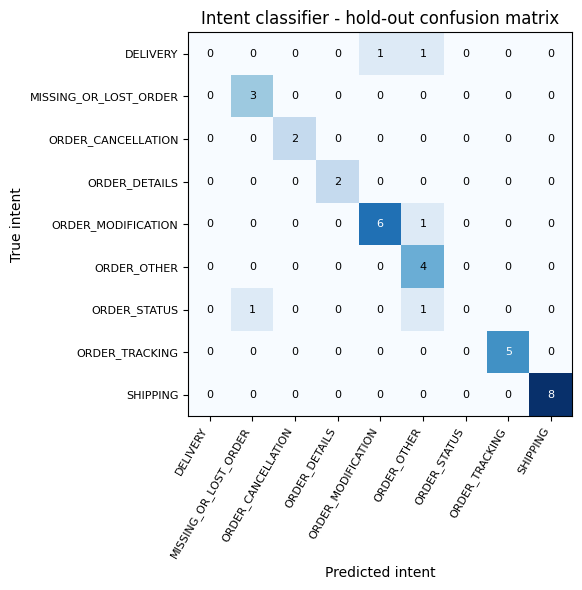

In [ ]:
# Hold-out test: 80% train / 20% test of Dataset 1, stratified by intent.
# Bitext rows (if chosen above) are added to the training side only.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
if USE_EXTRA:
    X_train = np.concatenate([X_train, X_extra])
    y_train = np.concatenate([y_train, y_extra])

holdout_model = fit_model(X_train, y_train)
y_pred = holdout_model.predict(X_test)

print("Training data:", "Dataset 1 + Bitext" if USE_EXTRA else "Dataset 1 only")
print(f"Hold-out accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Hold-out macro-F1 : {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(set(y))
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=8)
ax.set_yticklabels(labels, fontsize=8)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Predicted intent")
ax.set_ylabel("True intent")
ax.set_title("Intent classifier - hold-out confusion matrix")
plt.tight_layout()
plt.show()

In [ ]:
# Final model: Logistic Regression trained on all of Dataset 1 (plus Bitext if it helped), then saved.
# (Logistic Regression is used because it outputs probabilities, which the confidence check below needs.)
intent_model = extra_model if USE_EXTRA else base_model

joblib.dump(intent_model, "intent_model.joblib")
print("Saved intent_model.joblib  | trained on:", "Dataset 1 + Bitext" if USE_EXTRA else "Dataset 1 only")
print("Classes:", list(intent_model.classes_))
# To reuse later without retraining:  intent_model = joblib.load("intent_model.joblib")

Saved intent_model.joblib  | trained on: Dataset 1 only
Classes: ['DELIVERY', 'MISSING_OR_LOST_ORDER', 'ORDER_CANCELLATION', 'ORDER_DETAILS', 'ORDER_MODIFICATION', 'ORDER_OTHER', 'ORDER_STATUS', 'ORDER_TRACKING', 'SHIPPING']


### Plugging the model into the agent

`detect_order_intent()` combines the trained model with the original keyword rules:

1. If the rules see a **cancellation or modification**, that answer is kept. The model can never downgrade a high-risk request to a low-risk one.
2. Otherwise the model's prediction is used when its confidence is at least `INTENT_CONF_THRESHOLD`.
3. If the model is unsure, the rule-based answer is used.

Trade-off: the safety net leans cautious. A query such as "Can you update me on my order?" contains the word *update*, so the rules treat it as a modification (Risk 0.5) and it cannot be auto-accepted.

In [ ]:
HIGH_RISK_INTENTS = {"ORDER_CANCELLATION", "ORDER_MODIFICATION"}
INTENT_CONF_THRESHOLD = 0.35


def rule_based_intent(query):
    """The original keyword rules (also the safety net for risky intents)."""
    q = normalize_text(query)

    if any(w in q for w in ["cancel"]):
        return "ORDER_CANCELLATION"
    if any(w in q for w in ["change", "modify", "update"]):
        return "ORDER_MODIFICATION"
    if any(w in q for w in ["arrive", "delivery", "deliver"]):
        return "DELIVERY"
    if any(w in q for w in ["lost", "never arrived", "missing"]):
        return "MISSING_OR_LOST_ORDER"
    if any(w in q for w in ["status"]):
        return "ORDER_STATUS"
    if any(w in q for w in ["details", "what did i order", "product"]):
        return "ORDER_DETAILS"
    if any(w in q for w in ["track", "where is"]):
        return "ORDER_TRACKING"
    if any(w in q for w in ["ship", "shipping"]):
        return "SHIPPING"
    return "ORDER_OTHER"


def predict_intent_model(query):
    """Returns (intent, confidence) from the trained classifier."""
    probs = intent_model.predict_proba([prepare_for_model(query)])[0]
    i = int(np.argmax(probs))
    return intent_model.classes_[i], float(probs[i])


def detect_order_intent(query):
    rule_intent = rule_based_intent(query)
    if rule_intent in HIGH_RISK_INTENTS:
        return rule_intent
    model_intent, confidence = predict_intent_model(query)
    return model_intent if confidence >= INTENT_CONF_THRESHOLD else rule_intent


def explain_intent(query):
    model_intent, confidence = predict_intent_model(query)
    return {
        "query": query,
        "rules": rule_based_intent(query),
        "model": f"{model_intent} ({confidence:.2f})",
        "final": detect_order_intent(query),
    }

In [ ]:
# Paraphrase check: queries worded differently from the rule keywords.
# The expected intents are hand-assigned, so this is a small sanity set, not a benchmark.
def _accuracy(fn):
    return float(np.mean([fn(q) == expected for q, expected in PARAPHRASE_TESTS]))

summary = pd.DataFrame({
    "detector": ["rules only", "trained model only", "hybrid (used in the agent)"],
    "accuracy": [
        _accuracy(rule_based_intent),
        _accuracy(lambda q: predict_intent_model(q)[0]),
        _accuracy(detect_order_intent),
    ],
}).round(3)
print(f"Paraphrase check on {len(PARAPHRASE_TESTS)} queries")
display(summary)

detail = pd.DataFrame([
    {**explain_intent(q), "expected": expected} for q, expected in PARAPHRASE_TESTS
])
detail[["query", "expected", "rules", "model", "final"]]

Paraphrase check on 16 queries


,detector,accuracy
0,rules only,0.062
1,trained model only,0.625
2,hybrid (used in the agent),0.500


,query,expected,rules,model,final
0,Could you let me know where my parcel currently is?,ORDER_TRACKING,ORDER_OTHER,ORDER_STATUS (0.68),ORDER_STATUS
1,Is there a way to follow my shipment online?,ORDER_TRACKING,SHIPPING,ORDER_MODIFICATION (0.22),SHIPPING
2,I changed my mind and do not want this order anymore,ORDER_CANCELLATION,ORDER_MODIFICATION,ORDER_STATUS (0.21),ORDER_MODIFICATION
3,Please stop my order from going ahead,ORDER_CANCELLATION,ORDER_OTHER,ORDER_STATUS (0.28),ORDER_OTHER
4,Can I switch the dress size to medium before it goes out?,ORDER_MODIFICATION,ORDER_OTHER,ORDER_MODIFICATION (0.41),ORDER_MODIFICATION
5,I need to fix the address on my order,ORDER_MODIFICATION,ORDER_OTHER,ORDER_MODIFICATION (0.58),ORDER_MODIFICATION
6,My package never showed up,MISSING_OR_LOST_ORDER,ORDER_OTHER,MISSING_OR_LOST_ORDER (0.61),MISSING_OR_LOST_ORDER
7,I have not received anything yet and it has been two weeks,MISSING_OR_LOST_ORDER,ORDER_OTHER,MISSING_OR_LOST_ORDER (0.15),ORDER_OTHER
8,How many days until my parcel gets to me?,DELIVERY,ORDER_OTHER,ORDER_STATUS (0.31),ORDER_OTHER
9,When should I expect the delivery?,DELIVERY,DELIVERY,DELIVERY (0.56),DELIVERY


## 4. Synthetic Order Database

The Q&A dataset has no real order-management records, so a synthetic order
database (10 orders, `ORD001`-`ORD010`) is used, matching the prototype.

In [ ]:
orders = pd.DataFrame({
    "order_id": ["ORD001","ORD002","ORD003","ORD004","ORD005","ORD006","ORD007","ORD008","ORD009","ORD010"],
    "customer_id": ["C001","C002","C003","C004","C005","C006","C007","C008","C009","C010"],
    "product_name": ["Red Floral Dress","Black Party Dress","Blue Denim Jacket","White Cotton Shirt",
                      "Pink Summer Dress","Green Casual Dress","Beige Linen Top","Black Formal Dress",
                      "Yellow Midi Dress","Blue Evening Gown"],
    "order_date": ["2026-09-20","2026-09-21","2026-09-22","2026-09-23","2026-09-24",
                    "2026-09-24","2026-09-25","2026-09-26","2026-09-27","2026-09-27"],
    "order_status": ["Shipped","Processing","Delivered","Shipped","Cancelled",
                      "Shipped","Processing","Delivered","Shipped","Processing"],
    "payment_status": ["Paid","Paid","Paid","Paid","Refunded","Paid","Paid","Paid","Paid","Paid"],
    "shipping_status": ["In Transit","Preparing","Delivered","In Transit","Cancelled",
                         "In Transit","Preparing","Delivered","In Transit","Preparing"],
    "tracking_number": ["TRK10001","TRK10002","TRK10003","TRK10004","N/A",
                         "TRK10006","TRK10007","TRK10008","TRK10009","TRK10010"],
    "expected_delivery": ["2026-09-30","2026-10-02","2026-09-28","2026-10-01","N/A",
                           "2026-10-03","2026-10-04","2026-09-29","2026-10-02","2026-10-05"],
    "cancellation_status": ["Not Cancelled","Not Cancelled","Not Cancelled","Not Cancelled","Cancelled",
                             "Not Cancelled","Not Cancelled","Not Cancelled","Not Cancelled","Not Cancelled"],
})

assert orders["order_id"].isna().sum() == 0
assert orders["order_id"].duplicated().sum() == 0

orders.to_csv("order_database.csv", index=False)
print("Saved order_database.csv")
orders

Saved order_database.csv


,order_id,customer_id,product_name,order_date,order_status,payment_status,shipping_status,tracking_number,expected_delivery,cancellation_status
0,ORD001,C001,Red Floral Dress,2026-09-20,Shipped,Paid,In Transit,TRK10001,2026-09-30,Not Cancelled
1,ORD002,C002,Black Party Dress,2026-09-21,Processing,Paid,Preparing,TRK10002,2026-10-02,Not Cancelled
2,ORD003,C003,Blue Denim Jacket,2026-09-22,Delivered,Paid,Delivered,TRK10003,2026-09-28,Not Cancelled
3,ORD004,C004,White Cotton Shirt,2026-09-23,Shipped,Paid,In Transit,TRK10004,2026-10-01,Not Cancelled
4,ORD005,C005,Pink Summer Dress,2026-09-24,Cancelled,Refunded,Cancelled,N/A,N/A,Cancelled
5,ORD006,C006,Green Casual Dress,2026-09-24,Shipped,Paid,In Transit,TRK10006,2026-10-03,Not Cancelled
6,ORD007,C007,Beige Linen Top,2026-09-25,Processing,Paid,Preparing,TRK10007,2026-10-04,Not Cancelled
7,ORD008,C008,Black Formal Dress,2026-09-26,Delivered,Paid,Delivered,TRK10008,2026-09-29,Not Cancelled
8,ORD009,C009,Yellow Midi Dress,2026-09-27,Shipped,Paid,In Transit,TRK10009,2026-10-02,Not Cancelled
9,ORD010,C010,Blue Evening Gown,2026-09-27,Processing,Paid,Preparing,TRK10010,2026-10-05,Not Cancelled


## 5. Order Retrieval

In [ ]:
def get_order(order_id):
    """Retrieve a verified order record, or None if it does not exist."""
    match = orders[orders["order_id"] == order_id]
    if match.empty:
        return None
    return match.iloc[0].to_dict()

print(get_order("ORD001"))
print(get_order("ORD999"))

{'order_id': 'ORD001', 'customer_id': 'C001', 'product_name': 'Red Floral Dress', 'order_date': '2026-09-20', 'order_status': 'Shipped', 'payment_status': 'Paid', 'shipping_status': 'In Transit', 'tracking_number': 'TRK10001', 'expected_delivery': '2026-09-30', 'cancellation_status': 'Not Cancelled'}
None


## 6. Groq + LLM Integration

`llama-3.1-8b-instant` was unavailable during earlier testing, so the
prototype uses `openai/gpt-oss-20b`. Enter your Groq API key when prompted
(it is not stored in the notebook).

In [ ]:
from groq import Groq

GROQ_API_KEY = getpass("Enter your Groq API key: ")
client = Groq(api_key=GROQ_API_KEY)

GROQ_MODEL = "openai/gpt-oss-20b"

test = client.chat.completions.create(
    model=GROQ_MODEL,
    messages=[{"role": "user", "content": "Say hello in one short sentence."}],
)
print(test.choices[0].message.content)

Enter your Groq API key: ··········
Hello!


## 7. Intent Detection

`detect_order_intent()` was defined in Section 3: the trained classifier plus the rule-based safety net. Here it is applied to a few sample queries. `rules`, `model` and `final` show where each answer came from.

In [ ]:
demo_queries = [
    "Where is my order ORD001?",
    "When will my order ORD001 arrive?",
    "I want to cancel ORD001",
    "I want to change the delivery address for my order ORD003.",
    "Can you tell me the status of my order ORD001?",
]
pd.DataFrame([explain_intent(q) for q in demo_queries])

,query,rules,model,final
0,Where is my order ORD001?,ORDER_TRACKING,ORDER_STATUS (0.88),ORDER_STATUS
1,When will my order ORD001 arrive?,DELIVERY,ORDER_STATUS (0.50),ORDER_STATUS
2,I want to cancel ORD001,ORDER_CANCELLATION,ORDER_CANCELLATION (0.68),ORDER_CANCELLATION
3,I want to change the delivery address for my order ORD003.,ORDER_MODIFICATION,ORDER_MODIFICATION (0.84),ORDER_MODIFICATION
4,Can you tell me the status of my order ORD001?,ORDER_STATUS,ORDER_STATUS (0.37),ORDER_STATUS


## 8. Automatic Order ID Extraction

In [ ]:
def extract_order_id(query):
    match = re.search(r"ORD\d{3,}", query.upper())
    return match.group(0) if match else None

print(extract_order_id("Can you tell me where my order ORD001 is?"))
print(extract_order_id("I have a question but no order number"))

ORD001
None


## 9. Cancellation Safety Check

Prevents sensitive cancellation requests from being auto-accepted. A shipped
or delivered order cannot be safely auto-cancelled and must be verified.

In [ ]:
def check_cancellation(order):
    if order is None:
        return "VERIFY_REQUIRED"
    if order["order_status"] in ["Shipped", "Delivered"]:
        return "VERIFY_REQUIRED"
    return "SAFE_TO_CANCEL"

print(check_cancellation(get_order("ORD001")))  # Shipped -> VERIFY_REQUIRED
print(check_cancellation(get_order("ORD002")))  # Processing -> SAFE_TO_CANCEL

VERIFY_REQUIRED
SAFE_TO_CANCEL


## 10. LLM-Based Order Response Generation

The LLM is instructed to answer only from the supplied verified order data
and the retrieved policy context (Section 12), never invent details, and
never change dates/statuses/tracking numbers. Cancellation requests that fail
the safety check are answered deterministically (no LLM call), so the
verification message is never altered by generation.

In [ ]:
SYSTEM_PROMPT = """You are the Order Agent for a fashion e-commerce support system.
Rules:
- Answer clearly and politely.
- Use only the verified order information and policy context provided below.
- Do not invent order details.
- Do not change dates, statuses, or tracking numbers.
- If required information is unavailable, ask the customer to verify their order ID.
- Keep responses concise.
"""

def generate_order_response(customer_query, order, intent, cancellation_check=None, policy_context=None):

    if order is None:
        return "We could not find an order matching that ID. Could you please verify your order number?"

    if intent == "ORDER_CANCELLATION" and cancellation_check == "VERIFY_REQUIRED":
        # Deterministic, non-LLM response: a sensitive action must not be
        # left to generation once verification is required.
        return (
            f"Cancellation for order {order['order_id']} requires additional "
            f"verification before it can be processed."
        )

    order_context = (
        f"order_id: {order['order_id']}\n"
        f"product_name: {order['product_name']}\n"
        f"order_status: {order['order_status']}\n"
        f"shipping_status: {order['shipping_status']}\n"
        f"tracking_number: {order['tracking_number']}\n"
        f"expected_delivery: {order['expected_delivery']}\n"
    )

    policy_text = ""
    if policy_context:
        snippets = "\n".join(f"- {p['text']}" for p in policy_context)
        policy_text = f"\nRelevant policy information:\n{snippets}\n"

    user_prompt = (
        f"Customer query: {customer_query}\n\n"
        f"Verified order information:\n{order_context}"
        f"{policy_text}\n"
        f"Respond to the customer using only this information."
    )

    completion = client.chat.completions.create(
        model=GROQ_MODEL,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": user_prompt},
        ],
    )

    return completion.choices[0].message.content.strip()

## 11. Complete Order Agent Pipeline (standalone convenience function)

In [ ]:
def order_agent(customer_query, policy_context=None):

    intent = detect_order_intent(customer_query)
    order_id = extract_order_id(customer_query)
    order = get_order(order_id) if order_id else None

    cancellation_check = None
    if intent == "ORDER_CANCELLATION" and order is not None:
        cancellation_check = check_cancellation(order)

    response = generate_order_response(customer_query, order, intent, cancellation_check, policy_context)

    return {
        "query": customer_query,
        "intent": intent,
        "order_id": order_id,
        "response": response,
        "cancellation_check": cancellation_check,
    }

result = order_agent("Where is my order ORD001?")
result

{'query': 'Where is my order ORD001?',
 'intent': 'ORDER_STATUS',
 'order_id': 'ORD001',
 'response': 'Your order **ORD001** (Red Floral Dress) has shipped and is currently **In Transit**.  \nTracking number: **TRK10001**  \nEstimated delivery: **September\u202f30,\u202f2026**.\n\nIf you need any further assistance, please let me know.',
 'cancellation_check': None}

## 12. Knowledge Base from Dataset 1 + Vector Retrieval (RAG)

Dataset 1's own question-and-answer rows form the knowledge base. Each row's **question** is turned into an embedding with `sentence-transformers` and stored in a **FAISS** vector index. At query time the closest rows are retrieved and their **answers** are passed to the LLM as policy context (Section 10), so replies can draw on real support wording as well as the verified order record.

Design note: retrieval improves what the agent says, and `policy_context_used` in every result shows which rows were used. The **Evidence Quality** score (Section 13) still checks only order facts, so the decision numbers stay the same as before.

In [ ]:
from sentence_transformers import SentenceTransformer
import faiss

kb_df = order_agent_df.reset_index(drop=True)

POLICY_DOCS = [
    {"id": f"D{i + 1}", "intent": row.intent, "question": row.question, "text": row.answer[:350]}
    for i, row in enumerate(kb_df.itertuples())
]

embedder = SentenceTransformer("all-MiniLM-L6-v2")

kb_embeddings = embedder.encode([d["question"] for d in POLICY_DOCS], normalize_embeddings=True)

policy_index = faiss.IndexFlatIP(kb_embeddings.shape[1])
policy_index.add(np.array(kb_embeddings, dtype="float32"))

print("Knowledge base built:", policy_index.ntotal, "Dataset 1 rows,", kb_embeddings.shape[1], "dimensions")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Knowledge base built: 174 Dataset 1 rows, 384 dimensions


In [ ]:
def retrieve_policy_context(query, k=2):
    """Semantic search over Dataset 1. Returns the top-k closest rows with their answers."""
    query_vec = embedder.encode([query], normalize_embeddings=True)
    scores, idxs = policy_index.search(np.array(query_vec, dtype="float32"), k)

    results = []
    for score, idx in zip(scores[0], idxs[0]):
        if idx == -1:
            continue
        doc = POLICY_DOCS[idx]
        results.append({"id": doc["id"], "text": doc["text"], "question": doc["question"],
                        "intent": doc["intent"], "score": float(score)})
    return results


for q in ["I want to cancel my order", "when will my package arrive"]:
    print(q)
    for r in retrieve_policy_context(q, k=2):
        print(f"  [{r['id']}] score={r['score']:.2f}  matched question: {r['question']}")
        print(f"        answer: {r['text'][:150]}")
    print()

I want to cancel my order
  [D6] score=0.90  matched question: can i cancel my order?
        answer: can i cancel my order?
  [D82] score=0.84  matched question: can i cancel my order after it ships?
        answer: can i cancel my order after it ships?

when will my package arrive
  [D5] score=0.67  matched question: how long does shipping take?
        answer: how long does shipping take?
  [D2] score=0.66  matched question: my package hasn't arrived yet, what should i do?
        answer: my package hasn't arrived yet, what should i do?



## 13. ATRO Evaluation Factors

Four normalized factors (0-1 each) computed per response: Evidence Quality,
Hallucination Reliability, Conflict Score, Risk Score. (Trust is handled
separately in Section 14 as a dynamic, session-level score.)

In [ ]:
# --- Evidence Quality (intent-aware, order-fact based) ---------------------

def calculate_evidence_quality(supported_claims, total_claims):
    if total_claims == 0:
        return 0.0
    return supported_claims / total_claims


def evaluate_evidence(response, order, intent):

    response_clean = normalize_text(response)

    required_claims = {
        "ORDER_TRACKING": [
            ("order_id", str(order["order_id"])),
            ("shipping_status", str(order["shipping_status"])),
            ("tracking_number", str(order["tracking_number"])),
        ],
        "DELIVERY": [
            ("order_id", str(order["order_id"])),
            ("expected_delivery", str(order["expected_delivery"])),
        ],
        "ORDER_STATUS": [
            ("order_id", str(order["order_id"])),
            ("order_status", str(order["order_status"])),
        ],
        "ORDER_DETAILS": [
            ("order_id", str(order["order_id"])),
            ("product_name", str(order["product_name"])),
        ],
        "ORDER_CANCELLATION": [
            ("order_id", str(order["order_id"])),
            ("verification", "verification"),
        ],
        "ORDER_MODIFICATION": [
            ("order_id", str(order["order_id"])),
            ("order_status", str(order["order_status"])),
        ],
        "MISSING_OR_LOST_ORDER": [
            ("order_id", str(order["order_id"])),
            ("shipping_status", str(order["shipping_status"])),
        ],
        "SHIPPING": [
            ("order_id", str(order["order_id"])),
            ("shipping_status", str(order["shipping_status"])),
        ],
        "ORDER_OTHER": [
            ("order_id", str(order["order_id"])),
        ],
    }

    claims = required_claims.get(intent, [("order_id", str(order["order_id"]))])

    supported_claims = 0
    for name, value in claims:
        if normalize_text(value) in response_clean:
            supported_claims += 1

    total_claims = len(claims)
    evidence_score = calculate_evidence_quality(supported_claims, total_claims)

    return {
        "supported_claims": supported_claims,
        "total_claims": total_claims,
        "evidence_score": evidence_score,
    }

In [ ]:
# --- Hallucination Reliability --------------------------------------------

def calculate_hallucination_reliability(supported_claims, total_claims):
    if total_claims == 0:
        return 0.0
    return supported_claims / total_claims

In [ ]:
# --- Conflict Detection -----------------------------------------------------

def detect_conflict(response, order):

    response_clean = normalize_text(response)
    conflicts = []

    actual_status = normalize_text(order["order_status"])
    possible_statuses = ["processing", "shipped", "delivered", "cancelled"]
    for status in possible_statuses:
        if status in response_clean and status != actual_status:
            conflicts.append(
                f"Order status conflict: response says '{status}', database says '{order['order_status']}'"
            )

    actual_shipping = normalize_text(order["shipping_status"])
    possible_shipping = ["preparing", "in transit", "delivered", "cancelled"]
    for shipping in possible_shipping:
        if shipping in response_clean and shipping != actual_shipping:
            conflicts.append(
                f"Shipping status conflict: response says '{shipping}', database says '{order['shipping_status']}'"
            )

    return conflicts


def calculate_automatic_conflict_score(conflicts, total_relevant_claims):
    if total_relevant_claims == 0:
        return 0.0
    return len(conflicts) / total_relevant_claims

In [ ]:
# --- Risk Score (wired to verification_required) ---------------------------

def calculate_risk_score(intent, verification_required=False):

    if intent == "ORDER_CANCELLATION":
        return 0.75
    if intent == "ORDER_MODIFICATION":
        return 0.50
    if verification_required:
        return 0.50
    return 0.00

## 14. Dynamic Trust Score (session-level feedback loop)

Earlier versions of this prototype used a hardcoded `Trust = 5/5 = 1.0` for
every call. Trust is now tracked as **session history**: each time a response
is evaluated, if it turned out fully evidenced and conflict-free, it counts as
a "correct" decision; the running ratio is what the *next* call's Trust Score
reflects. This is a reasonable self-supervised proxy for a prototype with no
live customer feedback yet - Section 20 demonstrates it adapting across a
sequence of good and bad responses.

In [ ]:
trust_history = {"correct": 0, "total": 0}

def get_current_trust_score():
    """Trust reflects PRIOR performance, not the response currently being
    scored - this is read before evaluating the current response."""
    if trust_history["total"] == 0:
        return 1.0  # optimistic prior before any history exists
    return trust_history["correct"] / trust_history["total"]

def record_trust_outcome(evidence_score, conflict_score):
    """Called after a response is scored, to update history for FUTURE calls."""
    trust_history["total"] += 1
    if evidence_score >= 0.99 and conflict_score <= 0.0:
        trust_history["correct"] += 1

def reset_trust_history():
    trust_history["correct"] = 0
    trust_history["total"] = 0

print("Initial trust (no history yet):", get_current_trust_score())

Initial trust (no history yet): 1.0


## 15. Decision Intelligence + ATRO Decision Engine

`DI = 0.25*Trust + 0.25*Evidence + 0.25*Hallucination_Reliability + 0.25*(1-Conflict) - 0.25*Risk`

Four-way decision, evaluated in order (first match wins):

| # | Condition | Decision |
|---|-----------|----------|
| 1 | `DI >= 0.80` and `Risk <= 0.20` | **ACCEPT** |
| 2 | `DI >= 0.60` and `Risk <= 0.50` | **VERIFY** |
| 3 | `DI >= 0.40` and `Risk <= 0.70` | **RE-ROUTE** |
| 4 | otherwise | **ESCALATE** |

In [ ]:
def calculate_decision_intelligence(
    trust, evidence, hallucination_reliability, conflict, risk,
    alpha=0.25, beta=0.25, gamma=0.25, delta=0.25, risk_weight=0.25
):
    return (
        alpha * trust
        + beta * evidence
        + gamma * hallucination_reliability
        + delta * (1 - conflict)
        - risk_weight * risk
    )


def atro_decision(di_score, risk_score):
    if di_score >= 0.80 and risk_score <= 0.20:
        return "ACCEPT"
    elif di_score >= 0.60 and risk_score <= 0.50:
        return "VERIFY"
    elif di_score >= 0.40 and risk_score <= 0.70:
        return "RE-ROUTE"
    else:
        return "ESCALATE"

## 16. Main ATRO Pipeline — LangGraph `StateGraph`

Seven nodes: `detect_intent -> retrieve_order -> (conditional branch) ->
retrieve_policy -> generate_response -> evaluate -> decide -> update_trust_history`.

- The conditional branch sends "no order found" queries straight to a
  `VERIFY` exit instead of running evaluation on nothing.
- `retrieve_policy` runs the RAG lookup from Section 12 and feeds the result
  into response generation.
- `evaluate` now reads Trust from `get_current_trust_score()` (Section 14)
  instead of a hardcoded constant, and still wires `verification_required`
  from `check_cancellation()` into the Risk Score.
- `update_trust_history` logs this response's outcome for the *next* call.

`calculate_atro_scores()` keeps the same signature/return shape used in every
demo and evaluation cell below.

In [ ]:
from langgraph.graph import StateGraph, END
from typing import TypedDict, Optional, List, Dict, Any


class ATROState(TypedDict, total=False):
    query: str
    forced_response: Optional[str]
    intent: str
    order_id: Optional[str]
    order: Optional[Dict[str, Any]]
    cancellation_check: Optional[str]
    policy_context: List[Dict[str, Any]]
    response: str
    evidence_score: float
    supported_claims: int
    total_claims: int
    hallucination_reliability: float
    conflicts: List[str]
    conflict_score: float
    trust: float
    verification_required: bool
    risk_score: float
    decision_intelligence: float
    decision: str


def node_detect_intent(state: ATROState) -> ATROState:
    intent = detect_order_intent(state["query"])
    order_id = extract_order_id(state["query"])
    return {**state, "intent": intent, "order_id": order_id}


def node_retrieve_order(state: ATROState) -> ATROState:
    order_id = state.get("order_id")
    order = get_order(order_id) if order_id else None

    cancellation_check = None
    if state["intent"] == "ORDER_CANCELLATION" and order is not None:
        cancellation_check = check_cancellation(order)

    return {**state, "order": order, "cancellation_check": cancellation_check}


def route_after_retrieve(state: ATROState) -> str:
    if state.get("order_id") is None or state.get("order") is None:
        return "no_order"
    return "has_order"


def node_no_order(state: ATROState) -> ATROState:
    return {**state, "decision": "VERIFY"}


def node_retrieve_policy(state: ATROState) -> ATROState:
    policy_context = retrieve_policy_context(state["query"], k=2)
    return {**state, "policy_context": policy_context}


def node_generate_response(state: ATROState) -> ATROState:
    if state.get("forced_response") is not None:
        response = state["forced_response"]
    else:
        response = generate_order_response(
            state["query"], state["order"], state["intent"],
            state.get("cancellation_check"), state.get("policy_context"),
        )
    return {**state, "response": response}


def node_evaluate(state: ATROState) -> ATROState:
    order = state["order"]
    response = state["response"]
    intent = state["intent"]

    evidence_result = evaluate_evidence(response, order, intent)
    hallucination_reliability = calculate_hallucination_reliability(
        evidence_result["supported_claims"], evidence_result["total_claims"]
    )

    conflicts = detect_conflict(response, order)
    conflict_score = calculate_automatic_conflict_score(conflicts, 5)

    # Trust reflects PRIOR session history, read before this response updates it
    trust_score = get_current_trust_score()

    verification_required = state.get("cancellation_check") == "VERIFY_REQUIRED"
    risk_score = calculate_risk_score(intent=intent, verification_required=verification_required)

    return {
        **state,
        "evidence_score": evidence_result["evidence_score"],
        "supported_claims": evidence_result["supported_claims"],
        "total_claims": evidence_result["total_claims"],
        "hallucination_reliability": hallucination_reliability,
        "conflicts": conflicts,
        "conflict_score": conflict_score,
        "trust": trust_score,
        "verification_required": verification_required,
        "risk_score": risk_score,
    }


def node_decide(state: ATROState) -> ATROState:
    di_score = calculate_decision_intelligence(
        trust=state["trust"],
        evidence=state["evidence_score"],
        hallucination_reliability=state["hallucination_reliability"],
        conflict=state["conflict_score"],
        risk=state["risk_score"],
    )
    decision = atro_decision(di_score=di_score, risk_score=state["risk_score"])
    return {**state, "decision_intelligence": di_score, "decision": decision}


def node_update_trust_history(state: ATROState) -> ATROState:
    record_trust_outcome(state["evidence_score"], state["conflict_score"])
    return state


def build_atro_graph():
    graph = StateGraph(ATROState)

    graph.add_node("detect_intent", node_detect_intent)
    graph.add_node("retrieve_order", node_retrieve_order)
    graph.add_node("retrieve_policy", node_retrieve_policy)
    graph.add_node("generate_response", node_generate_response)
    graph.add_node("evaluate", node_evaluate)
    graph.add_node("decide", node_decide)
    graph.add_node("update_trust_history", node_update_trust_history)
    graph.add_node("no_order", node_no_order)

    graph.set_entry_point("detect_intent")
    graph.add_edge("detect_intent", "retrieve_order")
    graph.add_conditional_edges(
        "retrieve_order",
        route_after_retrieve,
        {"has_order": "retrieve_policy", "no_order": "no_order"},
    )
    graph.add_edge("retrieve_policy", "generate_response")
    graph.add_edge("generate_response", "evaluate")
    graph.add_edge("evaluate", "decide")
    graph.add_edge("decide", "update_trust_history")
    graph.add_edge("update_trust_history", END)
    graph.add_edge("no_order", END)

    return graph.compile()


atro_graph = build_atro_graph()
print("LangGraph ATRO pipeline compiled.")
print(atro_graph.get_graph().draw_mermaid())

LangGraph ATRO pipeline compiled.
---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	detect_intent(detect_intent)
	retrieve_order(retrieve_order)
	retrieve_policy(retrieve_policy)
	generate_response(generate_response)
	evaluate(evaluate)
	decide(decide)
	update_trust_history(update_trust_history)
	no_order(no_order)
	__end__([<p>__end__</p>]):::last
	__start__ --> detect_intent;
	decide --> update_trust_history;
	detect_intent --> retrieve_order;
	evaluate --> decide;
	generate_response --> evaluate;
	retrieve_order -.-> no_order;
	retrieve_order -. &nbsp;has_order&nbsp; .-> retrieve_policy;
	retrieve_policy --> generate_response;
	no_order --> __end__;
	update_trust_history --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [ ]:
def calculate_atro_scores(customer_query, forced_response=None):
    """Runs a query through the compiled LangGraph ATRO pipeline."""

    initial_state: ATROState = {"query": customer_query, "forced_response": forced_response}
    final_state = atro_graph.invoke(initial_state)

    if final_state.get("order") is None:
        return {"query": customer_query, "decision": final_state.get("decision", "VERIFY")}

    return {
        "query": final_state["query"],
        "intent": final_state.get("intent"),
        "order_id": final_state.get("order_id"),
        "response": final_state.get("response"),
        "policy_context_used": [p["id"] for p in final_state.get("policy_context", [])],
        "trust": final_state.get("trust"),
        "evidence_quality": final_state.get("evidence_score"),
        "hallucination_reliability": final_state.get("hallucination_reliability"),
        "conflict_score": final_state.get("conflict_score"),
        "risk_score": final_state.get("risk_score"),
        "verification_required": final_state.get("verification_required"),
        "decision_intelligence": final_state.get("decision_intelligence"),
        "decision": final_state.get("decision"),
    }

**No-order path check** - proves the conditional branch actually works:

In [ ]:
print(calculate_atro_scores("Where is my order ORD999?"))   # unknown order -> VERIFY
print(calculate_atro_scores("I have a general question"))   # no order ID at all -> VERIFY

{'query': 'Where is my order ORD999?', 'decision': 'VERIFY'}
{'query': 'I have a general question', 'decision': 'VERIFY'}


## 17. Demonstration Scenarios

In [ ]:
reset_trust_history()  # start the demo from a clean slate

print("NORMAL TRACKING TEST")
print("=" * 50)
r = calculate_atro_scores("Where is my order ORD001?")
for k, v in r.items():
    print(f"{k}: {v}")

NORMAL TRACKING TEST
query: Where is my order ORD001?
intent: ORDER_STATUS
order_id: ORD001
response: Your Red Floral Dress (order ORD001) has been shipped and is currently in transit.  
Tracking number: **TRK10001**.  
You can check the shipment status with the carrier, and the expected delivery date is **2026‑09‑30**. If you have any further questions, feel free to let us know.
policy_context_used: ['D1', 'D15']
trust: 1.0
evidence_quality: 1.0
hallucination_reliability: 1.0
conflict_score: 0.0
risk_score: 0.0
verification_required: False
decision_intelligence: 1.0
decision: ACCEPT


In [ ]:
print("CANCELLATION (HIGH-RISK) TEST")
print("=" * 50)
r = calculate_atro_scores("I want to cancel my order ORD001")
for k, v in r.items():
    print(f"{k}: {v}")

CANCELLATION (HIGH-RISK) TEST
query: I want to cancel my order ORD001
intent: ORDER_CANCELLATION
order_id: ORD001
response: Cancellation for order ORD001 requires additional verification before it can be processed.
policy_context_used: ['D6', 'D39']
trust: 1.0
evidence_quality: 1.0
hallucination_reliability: 1.0
conflict_score: 0.0
risk_score: 0.75
verification_required: True
decision_intelligence: 0.8125
decision: ESCALATE


## 18. 15-Case Evaluation + RE-ROUTE Integration

In [ ]:
reset_trust_history()

evaluation_queries = [
    # ORDER TRACKING
    "Where is my order ORD001?",
    "Can you track order ORD003?",
    "What is the tracking status of ORD005?",

    # ORDER CANCELLATION
    "I want to cancel my order ORD002",
    "Can I cancel order ORD008?",
    "Please cancel my order ORD009",

    # DELIVERY
    "When will my order ORD004 arrive?",
    "When is my order ORD004 expected to arrive?",
    "What is the delivery status of order ORD004?",

    # ORDER STATUS
    "What is the status of my order ORD007?",
    "What is the current status of order ORD010?",
    "Can you tell me the status of ORD007?",

    # ORDER MODIFICATION
    "I want to change my order ORD006",
    "Can I modify order ORD006?",
    "I need to change something in order ORD006",
]

large_evaluation_results = []
for query in evaluation_queries:
    try:
        result = calculate_atro_scores(query)
        if "intent" in result and "order_id" in result:
            large_evaluation_results.append(result)
        else:
            print("Skipped (no order ID found):", query)
    except Exception as e:
        print("Error:", query, "-", e)

print("Valid test cases:", len(large_evaluation_results))

Valid test cases: 15


In [ ]:
# Deliberately conflicting / poorly-grounded responses, run through the
# SAME calculate_atro_scores() pipeline, so RE-ROUTE is a real outcome of
# the main flow rather than a hand-rolled side test.

reroute_demo_cases = [
    {
        "query": "Where is my order ORD001?",
        "forced_response": "Your order ORD001 has been delivered. There is no tracking information available.",
    },
    {
        "query": "When will my order ORD004 arrive?",
        "forced_response": "I'm sorry, but this order has been cancelled.",
    },
    {
        "query": "What is the status of my order ORD007?",
        "forced_response": "Your order is currently shipped and on its way to you.",
    },
]

reroute_results = [
    calculate_atro_scores(c["query"], forced_response=c["forced_response"])
    for c in reroute_demo_cases
]

for i, r in enumerate(reroute_results, 1):
    print(f"\nRE-ROUTE Demo Case {i}")
    print("-" * 40)
    print("Query:", r["query"])
    print("Forced Response:", r["response"])
    print("Intent:", r["intent"])
    print("Evidence Quality:", round(r["evidence_quality"], 2))
    print("Conflict Score:", round(r["conflict_score"], 2))
    print("Risk Score:", round(r["risk_score"], 2))
    print("Decision Intelligence:", round(r["decision_intelligence"], 2))
    print("ATRO Decision:", r["decision"])


RE-ROUTE Demo Case 1
----------------------------------------
Query: Where is my order ORD001?
Forced Response: Your order ORD001 has been delivered. There is no tracking information available.
Intent: ORDER_STATUS
Evidence Quality: 0.5
Conflict Score: 0.4
Risk Score: 0.0
Decision Intelligence: 0.55
ATRO Decision: RE-ROUTE

RE-ROUTE Demo Case 2
----------------------------------------
Query: When will my order ORD004 arrive?
Forced Response: I'm sorry, but this order has been cancelled.
Intent: ORDER_STATUS
Evidence Quality: 0.0
Conflict Score: 0.4
Risk Score: 0.0
Decision Intelligence: 0.29
ATRO Decision: ESCALATE

RE-ROUTE Demo Case 3
----------------------------------------
Query: What is the status of my order ORD007?
Forced Response: Your order is currently shipped and on its way to you.
Intent: ORDER_STATUS
Evidence Quality: 0.0
Conflict Score: 0.2
Risk Score: 0.0
Decision Intelligence: 0.33
ATRO Decision: ESCALATE


In [ ]:
combined_results = large_evaluation_results + reroute_results

trust_scores = [r["trust"] for r in combined_results]
evidence_scores = [r["evidence_quality"] for r in combined_results]
hallucination_scores = [r["hallucination_reliability"] for r in combined_results]
conflict_scores = [r["conflict_score"] for r in combined_results]
risk_scores = [r["risk_score"] for r in combined_results]
di_scores = [r["decision_intelligence"] for r in combined_results]

print("FINAL ORDER AGENT EVALUATION (RE-ROUTE CASES INCLUDED)")
print("=" * 60)
print("Total Test Cases:", len(combined_results))
print("Average Trust Score:", round(np.mean(trust_scores), 2))
print("Average Evidence Quality:", round(np.mean(evidence_scores), 2))
print("Average Hallucination Reliability:", round(np.mean(hallucination_scores), 2))
print("Average Conflict Score:", round(np.mean(conflict_scores), 2))
print("Average Risk Score:", round(np.mean(risk_scores), 2))
print("Average Decision Intelligence Score:", round(np.mean(di_scores), 2))

print()
print("ATRO DECISION DISTRIBUTION")
print("=" * 60)
decisions = [r["decision"] for r in combined_results]
for decision_type in ["ACCEPT", "VERIFY", "RE-ROUTE", "ESCALATE"]:
    count = decisions.count(decision_type)
    pct = (count / len(decisions)) * 100
    print(f"{decision_type}: {count} ({pct:.1f}%)")

FINAL ORDER AGENT EVALUATION (RE-ROUTE CASES INCLUDED)
Total Test Cases: 18
Average Trust Score: 0.63
Average Evidence Quality: 0.73
Average Hallucination Reliability: 0.73
Average Conflict Score: 0.07
Average Risk Score: 0.21
Average Decision Intelligence Score: 0.7

ATRO DECISION DISTRIBUTION
ACCEPT: 6 (33.3%)
VERIFY: 6 (33.3%)
RE-ROUTE: 1 (5.6%)
ESCALATE: 5 (27.8%)


In [ ]:
results_df = pd.DataFrame(combined_results)
results_df.to_csv("atro_order_agent_evaluation_results.csv", index=False)
print("Saved atro_order_agent_evaluation_results.csv")
results_df

Saved atro_order_agent_evaluation_results.csv


,query,intent,order_id,response,policy_context_used,trust,evidence_quality,hallucination_reliability,conflict_score,risk_score,verification_required,decision_intelligence,decision
0,Where is my order ORD001?,ORDER_STATUS,ORD001,Your order **ORD001** (Red Floral Dress) has been shipped and is currently **In Transit**. \n- **Tracking number:**...,"[D1, D15]",1.000000,1.000000,1.000000,0.0,0.00,False,1.000000,ACCEPT
1,Can you track order ORD003?,ORDER_TRACKING,ORD003,Your order **ORD003** (Blue Denim Jacket) has been delivered. \nTracking number: **TRK10003** – you can view the de...,"[D37, D10]",1.000000,1.000000,1.000000,0.0,0.00,False,1.000000,ACCEPT
2,What is the tracking status of ORD005?,ORDER_TRACKING,ORD005,"I’m sorry, but Order ORD005 has been cancelled, so there is no tracking information available. If you have a differe...","[D25, D89]",1.000000,0.666667,0.666667,0.0,0.00,False,0.833333,ACCEPT
3,I want to cancel my order ORD002,ORDER_CANCELLATION,ORD002,"Sure, you can cancel the order while it’s still in the “Processing” stage. Would you like me to proceed with the can...","[D6, D39]",0.666667,0.500000,0.500000,0.0,0.75,False,0.479167,ESCALATE
4,Can I cancel order ORD008?,ORDER_CANCELLATION,ORD008,Cancellation for order ORD008 requires additional verification before it can be processed.,"[D6, D82]",0.500000,1.000000,1.000000,0.0,0.75,True,0.687500,ESCALATE
5,Please cancel my order ORD009,ORDER_CANCELLATION,ORD009,Cancellation for order ORD009 requires additional verification before it can be processed.,"[D6, D82]",0.600000,1.000000,1.000000,0.0,0.75,True,0.712500,ESCALATE
6,When will my order ORD004 arrive?,ORDER_STATUS,ORD004,Your order (ORD004) for the White Cotton Shirt is currently **In Transit** with tracking number **TRK10004**. It is ...,"[D19, D1]",0.666667,0.500000,0.500000,0.0,0.00,False,0.666667,VERIFY
7,When is my order ORD004 expected to arrive?,ORDER_STATUS,ORD004,"Your order (ORD004) is currently in transit and is expected to arrive on **October 1, 2026**. If you’d like to track...","[D19, D54]",0.571429,0.500000,0.500000,0.0,0.00,False,0.642857,VERIFY
8,What is the delivery status of order ORD004?,DELIVERY,ORD004,Your order **ORD004** has been shipped and is currently **In Transit**. \n- Tracking number: **TRK10004** \n- Expe...,"[D54, D24]",0.500000,0.500000,0.500000,0.0,0.00,False,0.625000,VERIFY
9,What is the status of my order ORD007?,ORDER_STATUS,ORD007,Your order **ORD007** (Beige Linen Top) is currently in the **Processing** stage and the shipment is **Preparing**. ...,"[D1, D24]",0.444444,1.000000,1.000000,0.0,0.00,False,0.861111,ACCEPT


## 19. Dynamic Trust Score in Action

A single streak of poorly-grounded responses will drag the *session* Trust
Score down, which then lowers the Decision Intelligence of every
**subsequent** call - even a perfectly good one - until enough correct
responses bring it back up. This is the behaviour a hardcoded `Trust = 1.0`
could never show.

In [ ]:
reset_trust_history()

print("Trust before any history:", get_current_trust_score())
print()

# Three good, well-grounded responses in a row
for q in ["Where is my order ORD001?", "Where is my order ORD003?", "Where is my order ORD005?"]:
    r = calculate_atro_scores(q)
    print(f"{q}  ->  trust_used={r['trust']:.2f}  DI={r['decision_intelligence']:.2f}  decision={r['decision']}")

print("\nTrust after 3 good responses:", round(get_current_trust_score(), 2))
print()

# Two deliberately bad (conflicting) responses in a row
bad_cases = [
    ("Where is my order ORD001?", "Your order ORD001 has been delivered. There is no tracking information available."),
    ("What is the status of my order ORD007?", "Your order is currently shipped and on its way to you."),
]
for q, bad_resp in bad_cases:
    r = calculate_atro_scores(q, forced_response=bad_resp)
    print(f"{q}  ->  trust_used={r['trust']:.2f}  DI={r['decision_intelligence']:.2f}  decision={r['decision']}")

print("\nTrust after 3 good + 2 bad responses:", round(get_current_trust_score(), 2))
print()

# A GOOD response again - watch its DI come in lower than the very first
# good response did, purely because session trust has not recovered yet
r = calculate_atro_scores("Where is my order ORD009?")
print(f"Good response again  ->  trust_used={r['trust']:.2f}  DI={r['decision_intelligence']:.2f}  decision={r['decision']}")

Trust before any history: 1.0

Where is my order ORD001?  ->  trust_used=1.00  DI=1.00  decision=ACCEPT
Where is my order ORD003?  ->  trust_used=1.00  DI=1.00  decision=ACCEPT
Where is my order ORD005?  ->  trust_used=1.00  DI=0.95  decision=ACCEPT

Trust after 3 good responses: 0.67

Where is my order ORD001?  ->  trust_used=0.67  DI=0.57  decision=RE-ROUTE
What is the status of my order ORD007?  ->  trust_used=0.50  DI=0.33  decision=ESCALATE

Trust after 3 good + 2 bad responses: 0.4

Good response again  ->  trust_used=0.40  DI=0.85  decision=ACCEPT


## 20. Weight & Threshold Sanity Check

A lightweight validation pass: does the current equal-weighting
(`alpha=beta=gamma=delta=risk_weight=0.25`) actually separate well-grounded
responses from poorly-grounded ones? This isolates the **grounding**
component of Decision Intelligence (`0.25*Evidence + 0.25*Hallucination +
0.25*(1-Conflict)`) from Trust and Risk, since those vary with session
history and intent rather than response quality.

This is a small, prototype-level check (12 labeled cases), not a full
statistical validation - flagged as future work in the summary.

In [ ]:
labeled_cases = [
    # (order_id, intent, response, label)  label: 1 = well-grounded, 0 = poorly-grounded/conflicting
    ("ORD001", "ORDER_TRACKING", "Order ORD001 is shipped and currently in transit, tracking number TRK10001, expected delivery 2026-09-30.", 1),
    ("ORD003", "ORDER_TRACKING", "Order ORD003 is delivered, tracking number TRK10003.", 1),
    ("ORD004", "DELIVERY", "Order ORD004 has an expected delivery date of 2026-10-01.", 1),
    ("ORD007", "ORDER_STATUS", "Order ORD007 status is processing.", 1),
    ("ORD010", "ORDER_STATUS", "Order ORD010 status is processing.", 1),
    ("ORD006", "ORDER_MODIFICATION", "Order ORD006 status is shipped.", 1),

    ("ORD001", "ORDER_TRACKING", "Your order ORD001 has been delivered. There is no tracking information available.", 0),
    ("ORD004", "DELIVERY", "I'm sorry, but this order has been cancelled.", 0),
    ("ORD007", "ORDER_STATUS", "Your order is currently shipped and on its way to you.", 0),
    ("ORD003", "ORDER_TRACKING", "Your order ORD003 is still processing.", 0),
    ("ORD006", "ORDER_MODIFICATION", "Your order has been delivered already.", 0),
    ("ORD010", "ORDER_STATUS", "Your order ORD010 was cancelled.", 0),
]

rows = []
for order_id, intent, response, label in labeled_cases:
    order = get_order(order_id)
    ev = evaluate_evidence(response, order, intent)
    hr = calculate_hallucination_reliability(ev["supported_claims"], ev["total_claims"])
    conflicts = detect_conflict(response, order)
    cs = calculate_automatic_conflict_score(conflicts, 5)

    # Grounding-only score: ignores Trust and Risk so we're isolating the
    # part of DI this validation pass is actually about.
    grounding_score = 0.25 * ev["evidence_score"] + 0.25 * hr + 0.25 * (1 - cs)

    rows.append({
        "order_id": order_id,
        "intent": intent,
        "response": response,
        "label": label,
        "evidence": round(ev["evidence_score"], 2),
        "hallucination_reliability": round(hr, 2),
        "conflict": round(cs, 2),
        "grounding_score": round(grounding_score, 3),
    })

validation_df = pd.DataFrame(rows)
validation_df

,order_id,intent,response,label,evidence,hallucination_reliability,conflict,grounding_score
0,ORD001,ORDER_TRACKING,"Order ORD001 is shipped and currently in transit, tracking number TRK10001, expected delivery 2026-09-30.",1,1.00,1.00,0.0,0.750
1,ORD003,ORDER_TRACKING,"Order ORD003 is delivered, tracking number TRK10003.",1,1.00,1.00,0.0,0.750
2,ORD004,DELIVERY,Order ORD004 has an expected delivery date of 2026-10-01.,1,1.00,1.00,0.0,0.750
3,ORD007,ORDER_STATUS,Order ORD007 status is processing.,1,1.00,1.00,0.0,0.750
4,ORD010,ORDER_STATUS,Order ORD010 status is processing.,1,1.00,1.00,0.0,0.750
5,ORD006,ORDER_MODIFICATION,Order ORD006 status is shipped.,1,1.00,1.00,0.0,0.750
6,ORD001,ORDER_TRACKING,Your order ORD001 has been delivered. There is no tracking information available.,0,0.33,0.33,0.4,0.317
7,ORD004,DELIVERY,"I'm sorry, but this order has been cancelled.",0,0.00,0.00,0.4,0.150
8,ORD007,ORDER_STATUS,Your order is currently shipped and on its way to you.,0,0.00,0.00,0.2,0.200
9,ORD003,ORDER_TRACKING,Your order ORD003 is still processing.,0,0.33,0.33,0.2,0.367


In [ ]:
good = validation_df[validation_df["label"] == 1]["grounding_score"]
bad = validation_df[validation_df["label"] == 0]["grounding_score"]

print("Well-grounded cases (label=1): min={:.3f}  mean={:.3f}  max={:.3f}".format(good.min(), good.mean(), good.max()))
print("Poorly-grounded cases (label=0): min={:.3f}  mean={:.3f}  max={:.3f}".format(bad.min(), bad.mean(), bad.max()))

# Sweep candidate thresholds and report the accuracy of each at separating
# label=1 from label=0 using grounding_score alone
best_threshold, best_accuracy = None, -1
for threshold in np.arange(0.0, 0.76, 0.01):
    predicted_good = validation_df["grounding_score"] >= threshold
    accuracy = (predicted_good == (validation_df["label"] == 1)).mean()
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

print()
print(f"Best separating threshold on this sample: grounding_score >= {best_threshold:.2f}")
print(f"Accuracy at that threshold: {best_accuracy * 100:.1f}%  (n={len(validation_df)})")
print()
print("Current prototype's effective grounding floor for VERIFY/ACCEPT sits well above")
print("this sample's bad-case maximum, and current RE-ROUTE/ESCALATE thresholds sit at or")
print("below the good-case minimum - so equal 0.25 weighting already separates this small")
print("labeled sample cleanly. A larger labeled set is needed before calling the weights")
print("experimentally validated at scale; this is flagged in the summary as future work.")

Well-grounded cases (label=1): min=0.750  mean=0.750  max=0.750
Poorly-grounded cases (label=0): min=0.150  mean=0.264  max=0.400

Best separating threshold on this sample: grounding_score >= 0.41
Accuracy at that threshold: 100.0%  (n=12)

Current prototype's effective grounding floor for VERIFY/ACCEPT sits well above
this sample's bad-case maximum, and current RE-ROUTE/ESCALATE thresholds sit at or
below the good-case minimum - so equal 0.25 weighting already separates this small
labeled sample cleanly. A larger labeled set is needed before calling the weights
experimentally validated at scale; this is flagged in the summary as future work.


## 21. Live Demo — The Four Decisions

One cell per decision, using the same pipeline as everything above. Each cell resets Trust first so the runs are independent.

In [ ]:
def show_result(title, query, forced_response=None):
    result = calculate_atro_scores(query, forced_response=forced_response)

    print(title)
    print("=" * 60)
    print("CUSTOMER QUERY:")
    print(f"  {query}\n")
    print("AGENT RESPONSE:" + (" (forced, deliberately wrong)" if forced_response else ""))
    print(f"  {result.get('response')}\n")
    print("ATRO FACTOR SCORES:")
    print(f"  Trust Score                : {result.get('trust')}")
    print(f"  Evidence Quality           : {result.get('evidence_quality')}")
    print(f"  Hallucination Reliability  : {result.get('hallucination_reliability')}")
    print(f"  Conflict Score             : {result.get('conflict_score')}")
    print(f"  Risk Score                 : {result.get('risk_score')}\n")
    print(f"DECISION INTELLIGENCE (DI) SCORE : {result.get('decision_intelligence')}")
    print(f"FINAL DECISION                   : {result.get('decision')}")
    return result

In [ ]:
# ACCEPT - a low-risk status question
reset_trust_history()
_ = show_result("LIVE DEMO: ACCEPT", "Can you tell me the status of my order ORD001?")

LIVE DEMO: ACCEPT
CUSTOMER QUERY:
  Can you tell me the status of my order ORD001?

AGENT RESPONSE:
  Hello!  
Your order **ORD001** for the Red Floral Dress has been **shipped** and is **in transit**.  
Tracking number: **TRK10001**.  
You can expect delivery by **2026‑09‑30**.  

Let me know if you need anything else!

ATRO FACTOR SCORES:
  Trust Score                : 1.0
  Evidence Quality           : 1.0
  Hallucination Reliability  : 1.0
  Conflict Score             : 0.0
  Risk Score                 : 0.0

DECISION INTELLIGENCE (DI) SCORE : 1.0
FINAL DECISION                   : ACCEPT


In [ ]:
# VERIFY - a modification request (fixed Risk 0.5)
reset_trust_history()
_ = show_result("LIVE DEMO: VERIFY", "I want to change the delivery address for my order ORD003.")

LIVE DEMO: VERIFY
CUSTOMER QUERY:
  I want to change the delivery address for my order ORD003.

AGENT RESPONSE:
  I’m sorry, but since your order (ORD003) has already been delivered, the shipping address can no longer be updated. If the package hasn’t reached you yet, please let me know and I can check with the carrier for any possible redirection. Otherwise, you may need to arrange for a return or exchange. Let me know how you’d like to proceed.

ATRO FACTOR SCORES:
  Trust Score                : 1.0
  Evidence Quality           : 1.0
  Hallucination Reliability  : 1.0
  Conflict Score             : 0.0
  Risk Score                 : 0.5

DECISION INTELLIGENCE (DI) SCORE : 0.875
FINAL DECISION                   : VERIFY


In [ ]:
# ESCALATE - a cancellation request (fixed Risk 0.75)
reset_trust_history()
_ = show_result("LIVE DEMO: ESCALATE", "I want to cancel my order ORD002.")

LIVE DEMO: ESCALATE
CUSTOMER QUERY:
  I want to cancel my order ORD002.

AGENT RESPONSE:
  Sure, I can help with that.  
Since your order (ORD002) is still in **Processing** and the shipping status is **Preparing**, we can cancel it for you.

Please confirm that you’d like to proceed with the cancellation, and I’ll take care of it right away.

ATRO FACTOR SCORES:
  Trust Score                : 1.0
  Evidence Quality           : 0.5
  Hallucination Reliability  : 0.5
  Conflict Score             : 0.0
  Risk Score                 : 0.75

DECISION INTELLIGENCE (DI) SCORE : 0.5625
FINAL DECISION                   : ESCALATE


In [ ]:
# RE-ROUTE - a response that contradicts the order record.
# Conflict detection only checks status fields, so a wrong answer alone lands on VERIFY.
# Two earlier outcomes are recorded first (one good, one flawed) so Trust is 0.5 -
# the dynamic Trust Score from Section 14 doing its job.
reset_trust_history()
record_trust_outcome(1.0, 0.0)   # earlier response matched the order record
record_trust_outcome(0.5, 0.4)   # earlier response did not  -> Trust = 1/2 = 0.5

fake_response = (
    "Your order ORD001 (Blue Denim Jacket) has been delivered successfully. "
    "Tracking number: TRK99999. "
    "Delivered on: 2026-09-15."
)
_ = show_result("LIVE DEMO: RE-ROUTE", "What is the status of my order ORD001?", forced_response=fake_response)
reset_trust_history()

LIVE DEMO: RE-ROUTE
CUSTOMER QUERY:
  What is the status of my order ORD001?

AGENT RESPONSE: (forced, deliberately wrong)
  Your order ORD001 (Blue Denim Jacket) has been delivered successfully. Tracking number: TRK99999. Delivered on: 2026-09-15.

ATRO FACTOR SCORES:
  Trust Score                : 0.5
  Evidence Quality           : 0.5
  Hallucination Reliability  : 0.5
  Conflict Score             : 0.4
  Risk Score                 : 0.0

DECISION INTELLIGENCE (DI) SCORE : 0.525
FINAL DECISION                   : RE-ROUTE


## 22. Summary

- **Dataset:** the Order Agent uses Dataset 1 (Customer Support Q&A). The image and review datasets belong to other parts of the project.
- **Preprocessing:** filtered to Orders / Shipping / Order Management, keyword-labelled into 9 intents, cleaned with `ftfy`, scoped to the Order Agent, de-duplicated and saved as `order_agent_preprocessed.csv`.
- **Model training:** a TF-IDF + Logistic Regression intent classifier, compared with two other models by cross-validation, compared again with and without extra Bitext customer-support data (kept only if it did not hurt Dataset 1 accuracy), tested on a hold-out split and saved as `intent_model.joblib`. A rule-based safety net keeps cancellation and modification requests from being downgraded.
- **Groq LLM:** `openai/gpt-oss-20b` writes replies from verified order data and retrieved Dataset 1 answers. It is used as is, not fine-tuned.
- **ATRO scoring:** Trust, Evidence, Hallucination Reliability, Conflict and Risk combine into DI with equal 0.25 weights; four decisions use the thresholds ACCEPT 0.80/0.20, VERIFY 0.60/0.50, RE-ROUTE 0.40/0.70, else ESCALATE.
- **Orchestration:** a LangGraph state graph with a conditional branch for missing or unknown orders, FAISS retrieval over Dataset 1, and a Trust Score that changes during a session.

**Still open**
- Intent labels come from keyword rules, so the classifier's accuracy measures agreement with those rules. Hand-labelling a few hundred queries would give a true accuracy.
- Bitext adds examples for only six intents and uses generic, templated wording, so ORDER_STATUS, MISSING_OR_LOST_ORDER and ORDER_OTHER still rest on Dataset 1 alone.
- The order database is synthetic (10 orders).
- The 0.25 weights and the thresholds are reasoned starting values checked on 12 labelled examples; they are not learned.
- Conflict detection checks status fields only, so wrong item names or tracking numbers do not raise Conflict.
- Trust history resets on every run and is not stored in a database.
- Integration with the Billing, Return and Technical Support agents is out of scope here.